In [1]:
import time
s = time.time()

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import warnings
warnings.filterwarnings('ignore')
# 假设 data 已经加载并且经过预处理
data =  pd.read_csv('life.csv')
X = data.drop(['Life expectancy '], axis=1)
y = data['Life expectancy ']
original_X = X.copy()

# 数据归一化
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

# 分割数据集
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 构建前馈神经网络模型
model = Sequential()
model.add(Dense(128, input_dim=x_train.shape[1], activation='relu'))  # 输入层和第一个隐藏层
model.add(Dense(64, activation='relu'))
model.add(Dense(32))# 第3个隐藏层
model.add(Dense(1))  # 输出层

# 编译模型
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mean_absolute_error'])

# 训练模型
history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2, verbose=-1)

# 评估模型
loss, mae = model.evaluate(x_test, y_test, verbose=0)
print(f'Test Mean Absolute Error: {mae}')

# 预测
y_pred = model.predict(x_test)

Epoch 1/10
Epoch 2/10
Epoch 3/10
Epoch 4/10
Epoch 5/10
Epoch 6/10
Epoch 7/10
Epoch 8/10
Epoch 9/10
Epoch 10/10
Test Mean Absolute Error: 2.8773648738861084
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


In [2]:
e = time.time()
e-s

3.182371139526367

In [3]:
from sklearn.metrics import r2_score,mean_squared_error,mean_squared_log_error,make_scorer

r2_score(y_test, y_pred)

0.8268736256128617

In [4]:
import shap

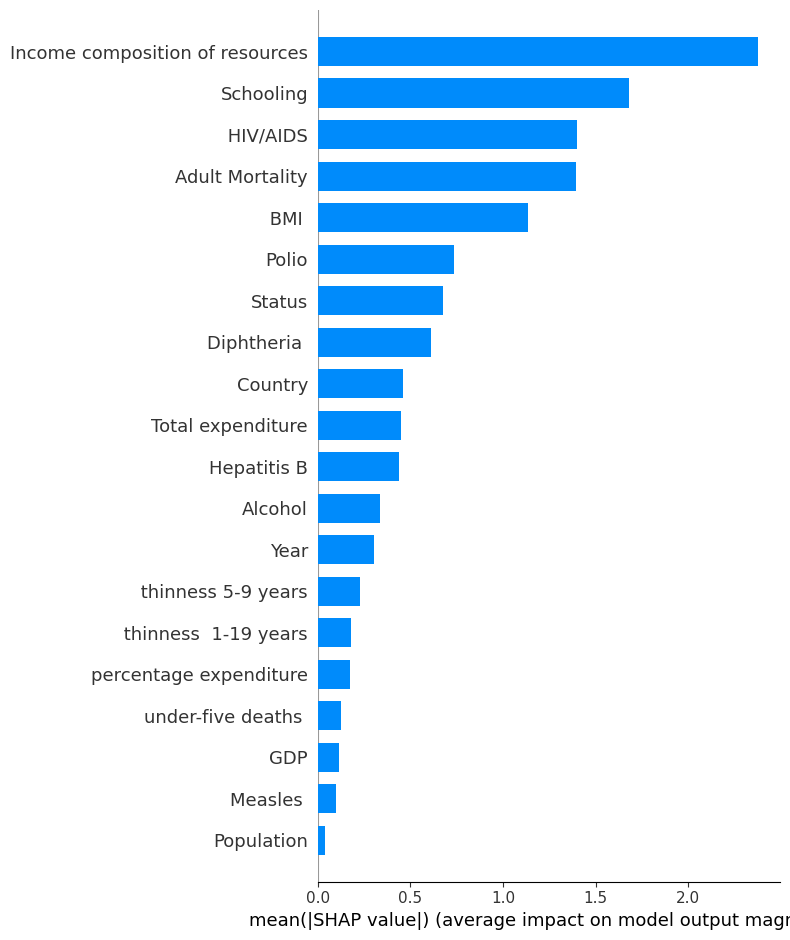

In [5]:
import time
s = time.time()

explainer = shap.Explainer(model,x_test)
shap_values = explainer.shap_values(x_test)
feature_names = original_X.columns.tolist()

# Visualize SHAP values
# shap.summary_plot(shap_values[0], x_test)
shap.summary_plot(shap_values, x_test, plot_type="bar", feature_names=feature_names)

In [6]:
# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=original_X.columns.tolist())
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)
shap_values_per_feature_sorted

infant deaths                      0.029797
Population                         0.037802
Measles                            0.096012
GDP                                0.115880
under-five deaths                  0.127720
percentage expenditure             0.175862
 thinness  1-19 years              0.178311
 thinness 5-9 years                0.228676
Year                               0.303943
Alcohol                            0.336603
Hepatitis B                        0.440266
Total expenditure                  0.452258
Country                            0.461684
Diphtheria                         0.612484
Status                             0.675009
Polio                              0.733912
 BMI                               1.137628
Adult Mortality                    1.392076
 HIV/AIDS                          1.402045
Schooling                          1.680671
Income composition of resources    2.376910
dtype: float64

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Assuming you have already calculated shap_values and x_test

# 最小-最大归一化到 [0, 1] 之间
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

infant deaths                      0.000000
Population                         0.003411
Measles                            0.028211
GDP                                0.036676
under-five deaths                  0.041720
percentage expenditure             0.062232
 thinness  1-19 years              0.063275
 thinness 5-9 years                0.084733
Year                               0.116801
Alcohol                            0.130716
Hepatitis B                        0.174882
Total expenditure                  0.179992
Country                            0.184008
Diphtheria                         0.248257
Status                             0.274896
Polio                              0.299992
 BMI                               0.471997
Adult Mortality                    0.580406
 HIV/AIDS                          0.584654
Schooling                          0.703364
Income composition of resources    1.000000
dtype: float64

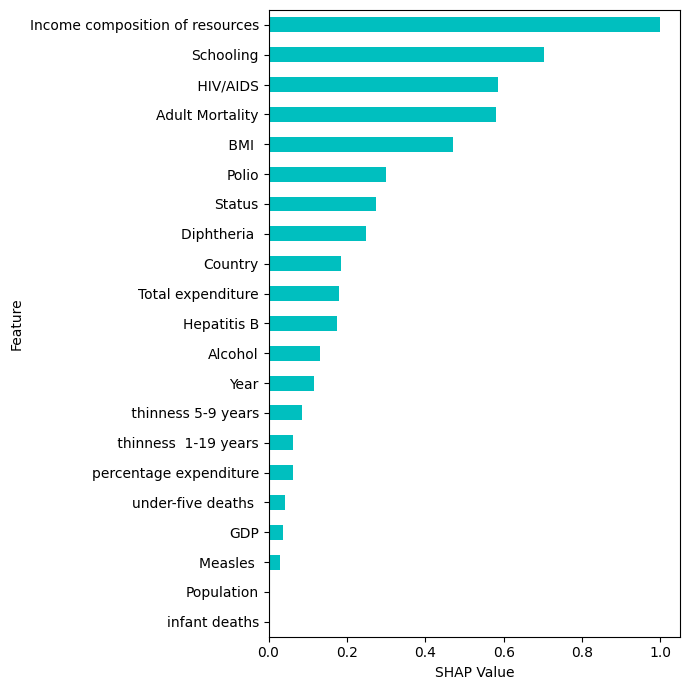

In [8]:
# Create a vertical figure for better spacing
plt.figure(figsize=(7, 7))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='c')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('shap_life_nn_normalized.eps', format='eps', dpi=300)

plt.show()

In [9]:
import time
s = time.time()
import shap

lgbexplainer = shap.SamplingExplainer(model.predict,x_test)
SamplingExplainer = lgbexplainer.shap_values(x_test)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 659us/step


  0%|          | 0/588 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 634us/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 989us/step
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 281us/step
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 305us/step
1/1 ━━━━━━━━━━━━━━━━━━━

  0%|          | 1/588 [00:01<15:45,  1.61s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 561us/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 221us/step
76/76 ━━━━━━━━━━━━━━━━━━━━ 0s 266us/step
20/20 ━━━━━━━━━━━━━━━━━

...

100%|█████████▉| 586/588 [15:18<00:03,  1.59s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 764us/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 642us/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 623us/step
127/127 ━━━━━━━━━━━━━━━━━━━━ 0s 232us/step
2/2 ━━━━━━━━━━━━━━

100%|█████████▉| 587/588 [15:19<00:01,  1.59s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 615us/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 819us/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 480us/step
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 234us/step
3/3 ━━━━━━━━━━━━━━━

100%|██████████| 588/588 [15:21<00:00,  1.57s/it]


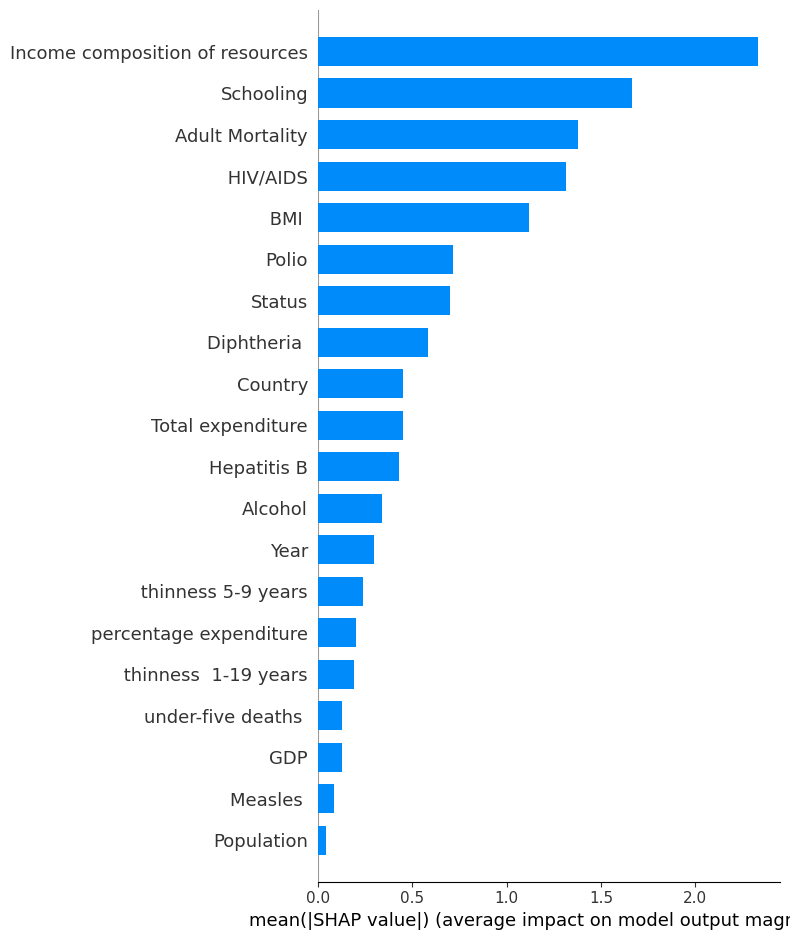

In [10]:
shap.summary_plot(SamplingExplainer, x_test, plot_type="bar", show=False, feature_names=feature_names)

In [11]:
e = time.time()
e-s

921.5794711112976

In [12]:
# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(SamplingExplainer, columns=original_X.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)
shap_values_per_feature_sorted


infant deaths                      0.029133
Population                         0.042665
Measles                            0.086344
GDP                                0.127070
under-five deaths                  0.127528
 thinness  1-19 years              0.189600
percentage expenditure             0.201536
 thinness 5-9 years                0.240037
Year                               0.295616
Alcohol                            0.341719
Hepatitis B                        0.430864
Total expenditure                  0.449249
Country                            0.452726
Diphtheria                         0.584374
Status                             0.700960
Polio                              0.718298
 BMI                               1.120185
 HIV/AIDS                          1.314410
Adult Mortality                    1.376698
Schooling                          1.666275
Income composition of resources    2.331563
dtype: float64

In [13]:
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

infant deaths                      0.000000
Population                         0.005877
Measles                            0.024848
GDP                                0.042536
under-five deaths                  0.042735
 thinness  1-19 years              0.069694
percentage expenditure             0.074878
 thinness 5-9 years                0.091600
Year                               0.115740
Alcohol                            0.135763
Hepatitis B                        0.174481
Total expenditure                  0.182466
Country                            0.183976
Diphtheria                         0.241154
Status                             0.291790
Polio                              0.299320
 BMI                               0.473869
 HIV/AIDS                          0.558226
Adult Mortality                    0.585279
Schooling                          0.711049
Income composition of resources    1.000000
dtype: float64

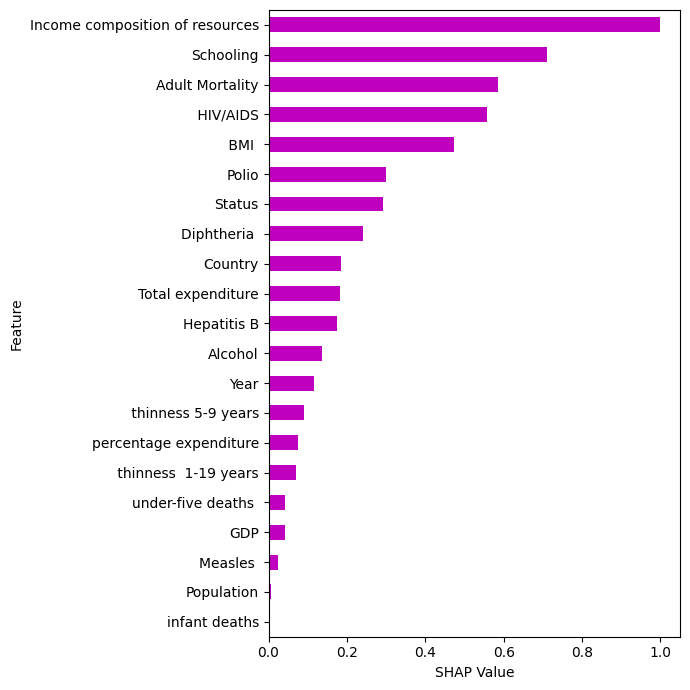

In [14]:
plt.figure(figsize=(7, 7))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='m')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('Samplingshap_life_nn_normalized.eps', format='eps', dpi=300)

plt.show()

In [26]:
import lime
import lime.lime_tabular

# 使用LIME解释器
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=x_train,
    feature_names=original_X.columns.tolist(),
    class_names=['Life expectancy'],
    mode='regression'
)

# 选择一个实例进行解释
i = 0  # 选择要解释的样本索引

exp = explainer.explain_instance(
    data_row=x_test[i],
    predict_fn=model.predict,
    num_features=len(original_X.columns)  # 设置要显示的特征数量
)

# Extract feature values and their weights
feature_values = exp.as_list()

feature_values

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step


[(' HIV/AIDS <= 0.00', 4.431854946006216),
 ('Diphtheria  <= 0.78', -2.5650088656289594),
 ('0.10 < Adult Mortality <= 0.20', 1.2312382878811317),
 ('Total expenditure <= 0.23', -1.1442343763073188),
 ('Country > 0.76', 1.1331165903777471),
 ('0.49 <  BMI  <= 0.64', 0.8567210039726538),
 ('0.50 < Schooling <= 0.59', -0.7958611705706993),
 ('Alcohol <= 0.06', -0.7037545450157688),
 ('0.54 < Income composition of resources <= 0.70', -0.5128045449383845),
 ('0.27 < Year <= 0.53', -0.3841642222177994),
 ('0.00 < percentage expenditure <= 0.02', -0.34247897767757995),
 ('0.82 < Hepatitis B <= 0.88', 0.3208030611084114),
 ('Population > 0.01', 0.3199385282987966),
 ('0.00 < GDP <= 0.03', 0.3136162215754969),
 ('0.11 <  thinness 5-9 years <= 0.25', 0.17706509021507363),
 ('Measles  > 0.00', -0.12859308078101875),
 ('0.12 <  thinness  1-19 years <= 0.25', -0.10841369605167306),
 ('0.00 < under-five deaths  <= 0.01', 0.09516328214738436),
 ('0.78 < Polio <= 0.94', 0.07137957708928756),
 ('0.00 

In [29]:
# 提取特征值及其权重
feature_values = exp.as_map()[1]

# 根据权重的绝对值对特征进行排序
sorted_features = sorted(feature_values, key=lambda x: abs(x[1]), reverse=True)

# 提取特征名称和权重
features = [original_X.columns[i] for i, _ in sorted_features]
weights = [weight for _, weight in sorted_features]

# 打印排序后的特征及其权重（按绝对值排序）
# print("Sorted features by absolute weight (from largest to smallest):")
for feature, weight in zip(features, weights):
    print(f"Feature: {feature}, Weight: {abs(weight)}")


Feature:  HIV/AIDS, Weight: 4.431854946006216
Feature: Diphtheria , Weight: 2.5650088656289594
Feature: Adult Mortality, Weight: 1.2312382878811317
Feature: Total expenditure, Weight: 1.1442343763073188
Feature: Country, Weight: 1.1331165903777471
Feature:  BMI , Weight: 0.8567210039726538
Feature: Schooling, Weight: 0.7958611705706993
Feature: Alcohol, Weight: 0.7037545450157688
Feature: Income composition of resources, Weight: 0.5128045449383845
Feature: Year, Weight: 0.3841642222177994
Feature: percentage expenditure, Weight: 0.34247897767757995
Feature: Hepatitis B, Weight: 0.3208030611084114
Feature: Population, Weight: 0.3199385282987966
Feature: GDP, Weight: 0.3136162215754969
Feature:  thinness 5-9 years, Weight: 0.17706509021507363
Feature: Measles , Weight: 0.12859308078101875
Feature:  thinness  1-19 years, Weight: 0.10841369605167306
Feature: under-five deaths , Weight: 0.09516328214738436
Feature: Polio, Weight: 0.07137957708928756
Feature: infant deaths, Weight: 0.0348453

In [30]:
abs_weights = [abs(weight) for weight in weights]
# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]
normalized_weights

[1.0,
 0.5787664300566577,
 0.2778155654644489,
 0.25818407647534813,
 0.25567546866552116,
 0.1933098024213747,
 0.17957744110914386,
 0.15879458005500838,
 0.11570878361000969,
 0.08668249004042665,
 0.07727666673436735,
 0.07238573126079055,
 0.07219065880915405,
 0.0707640988697325,
 0.03995281713239206,
 0.029015633938313103,
 0.02446237464278259,
 0.021472562461264923,
 0.016106027376552916,
 0.00786247249961565,
 0.0]

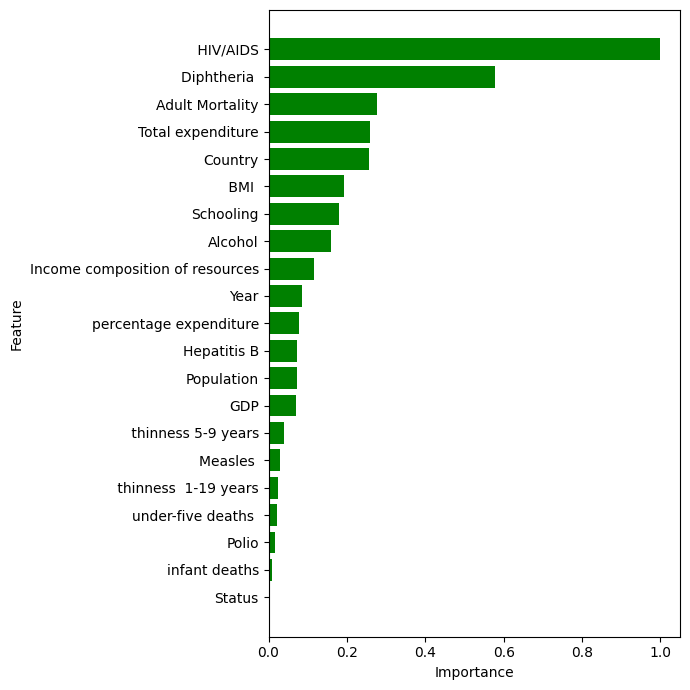

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# 计算绝对权重
abs_weights = [abs(weight) for weight in weights]

# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]

# 绘制归一化后的特征权重条形图
plt.figure(figsize=(7, 7))
plt.barh(features, normalized_weights, color='g')  # 使用归一化后的权重
plt.xlabel('Importance')  # 修改x轴标签
plt.ylabel('Feature')
# plt.title('LIME Feature Weights (Normalized Absolute Values)')  # 修改标题
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('lime_life_nn_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [32]:
from sklearn.inspection import permutation_importance
import numpy as np
result = permutation_importance(model, x_test, y_test, n_repeats=1, random_state=42, scoring='neg_mean_squared_error')

# 打印特征重要性
feature_names = original_X.columns.tolist()
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({importances[indices[f]]:.6f})")

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 662us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 597us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 556us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 526us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 544us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 549us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 577us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 527us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 528us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 554us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 530us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 561us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 519us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 498us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 562us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 599us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 567us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 588us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 582us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 536us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 495us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 554us/step
Feature ranking:
1. feature  HIV/AIDS (12.693046)
2. feature Income composition of resources (11.0

In [33]:
# 归一化处理
min_importance = np.min(importances)
max_importance = np.max(importances)
normalized_importances = (importances - min_importance) / (max_importance - min_importance)

# 按归一化后的重要性排序
indices = np.argsort(normalized_importances)[::-1]

# 打印归一化后的特征重要性
print("Feature ranking (normalized importance):")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({normalized_importances[indices[f]]:.6f})")

Feature ranking (normalized importance):
1. feature  HIV/AIDS (1.000000)
2. feature Income composition of resources (0.868501)
3. feature Adult Mortality (0.473603)
4. feature Schooling (0.438559)
5. feature Status (0.438341)
6. feature  BMI  (0.157409)
7. feature Polio (0.079419)
8. feature Diphtheria  (0.071505)
9. feature  thinness  1-19 years (0.061877)
10. feature  thinness 5-9 years (0.049379)
11. feature Hepatitis B (0.044276)
12. feature Alcohol (0.039044)
13. feature Year (0.033927)
14. feature Country (0.022522)
15. feature Total expenditure (0.016898)
16. feature Population (0.013469)
17. feature percentage expenditure (0.010345)
18. feature infant deaths (0.005178)
19. feature GDP (0.000747)
20. feature Measles  (0.000298)
21. feature under-five deaths  (0.000000)


In [34]:
# 创建一个数据框来存储特征及其重要性
feature_importance_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in indices],
    'Importance': normalized_importances[indices],
    'Std': std[indices]
})

# 按重要性排序
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=True)

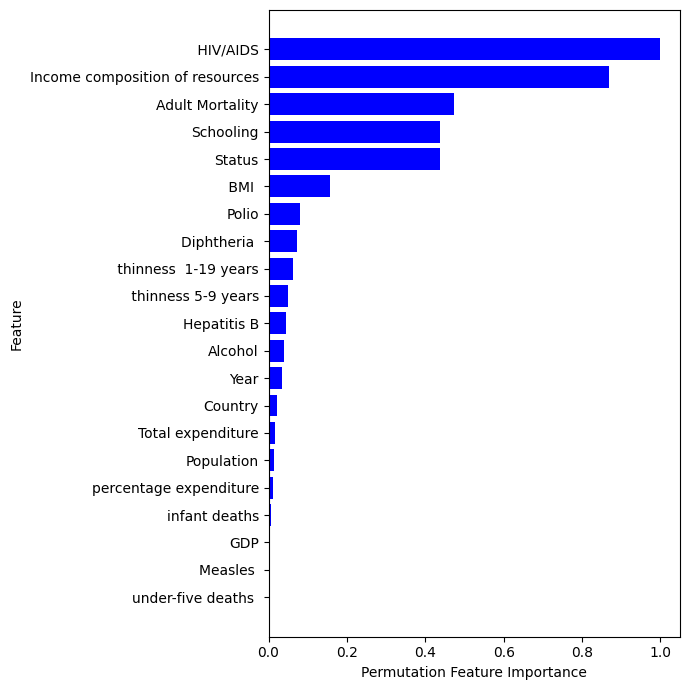

In [35]:
# 画图
plt.figure(figsize=(7, 7))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_df['Feature'], sorted_feature_importance_df['Importance'], color='b')
plt.ylabel('Feature')
plt.xlabel('Permutation Feature Importance')
# plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('Permutation_importance_life_nn_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()